# Exploratory Data Analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/hotel_bookings_clean.csv")
sns.set_theme(style="whitegrid")
BLUE = "#2a78d6"
print(df.shape)

(119208, 32)


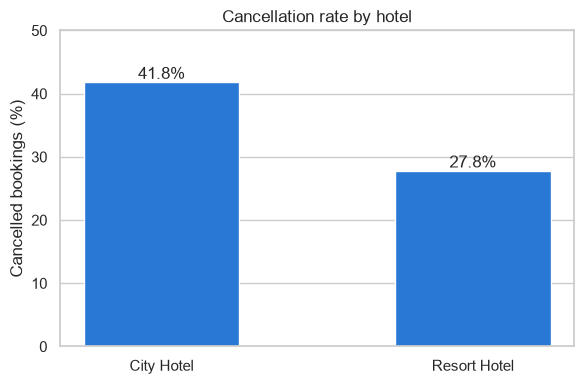

In [2]:
rate = df.groupby("hotel")["is_canceled"].mean() * 100

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(rate.index, rate.values, color=BLUE, width=0.5)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_ylim(0, 50)
ax.grid(axis="x", visible=False)
ax.set_title("Cancellation rate by hotel")
ax.set_ylabel("Cancelled bookings (%)")
plt.tight_layout()
plt.savefig("../images/01_cancel_rate_by_hotel.png", dpi=150)
plt.show()

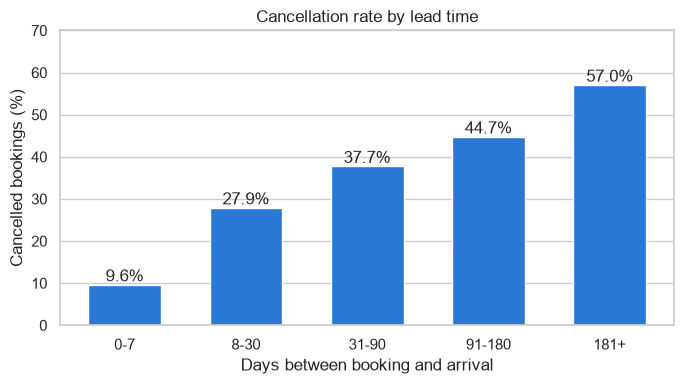

In [3]:
bins = [-1, 7, 30, 90, 180, 800]
labels = ["0-7", "8-30", "31-90", "91-180", "181+"]
df["lead_time_group"] = pd.cut(df["lead_time"], bins=bins, labels=labels)

rate = df.groupby("lead_time_group", observed=True)["is_canceled"].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rate.index, rate.values, color=BLUE, width=0.6)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_ylim(0, 70)
ax.grid(axis="x", visible=False)
ax.set_title("Cancellation rate by lead time")
ax.set_xlabel("Days between booking and arrival")
ax.set_ylabel("Cancelled bookings (%)")
plt.tight_layout()
plt.savefig("../images/02_cancel_rate_by_lead_time.png", dpi=150)
plt.show()

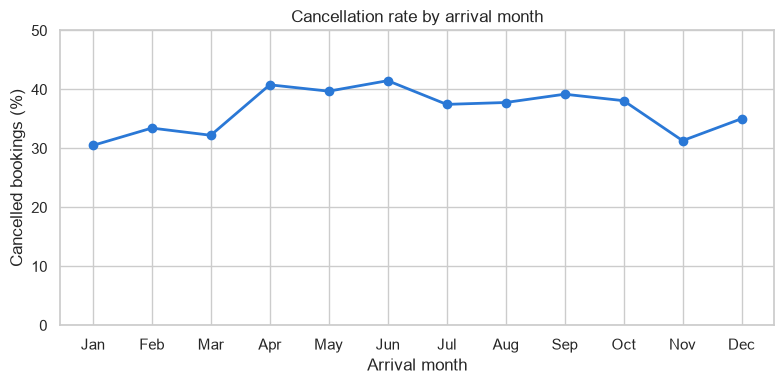

In [4]:
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]

monthly = df.groupby("arrival_date_month")["is_canceled"].mean() * 100
monthly = monthly.reindex(month_order)
short_names = [m[:3] for m in month_order]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(short_names, monthly.values, color=BLUE, linewidth=2, marker="o", markersize=6)
ax.set_ylim(0, 50)
ax.set_title("Cancellation rate by arrival month")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Cancelled bookings (%)")
plt.tight_layout()
plt.savefig("../images/03_cancel_rate_by_month.png", dpi=150)
plt.show()

In [5]:
def plot_cancel_rate(column, title, xlabel, filename):
    rate = df.groupby(column, observed=True)["is_canceled"].mean() * 100
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(rate.index.astype(str), rate.values, color=BLUE, width=0.6)
    ax.bar_label(ax.containers[0], fmt="%.1f%%")
    ax.set_ylim(0, rate.max() * 1.15)
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Cancelled bookings (%)")
    plt.tight_layout()
    plt.savefig(f"../images/{filename}", dpi=150)
    plt.show()
    return rate

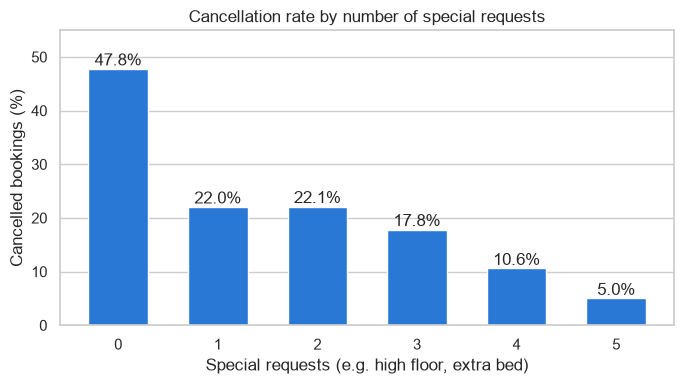

total_of_special_requests
0    47.768487
1    22.047434
2    22.127857
3    17.842823
4    10.588235
5     5.000000
Name: is_canceled, dtype: float64

In [6]:
plot_cancel_rate("total_of_special_requests",
                 "Cancellation rate by number of special requests",
                 "Special requests (e.g. high floor, extra bed)",
                 "04_cancel_rate_by_special_requests.png")

In [7]:
def plot_cancel_rate(column, title, xlabel, filename, rotate=0):    # NEW: rotate=0
    stats = df.groupby(column, observed=True)["is_canceled"].agg(["mean", "count"])  # NEW
    stats = stats[stats["count"] >= 30]                              # NEW
    rate = stats["mean"] * 100                                       # NEW
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(rate.index.astype(str), rate.values, color=BLUE, width=0.6)
    ax.bar_label(ax.containers[0], fmt="%.1f%%")
    ax.set_ylim(0, rate.max() * 1.15)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=rotate)                         # NEW
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Cancelled bookings (%)")
    plt.tight_layout()
    plt.savefig(f"../images/{filename}", dpi=150)
    plt.show()
    return rate

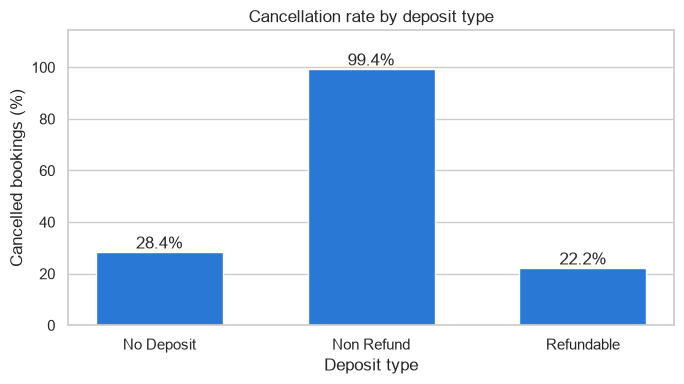

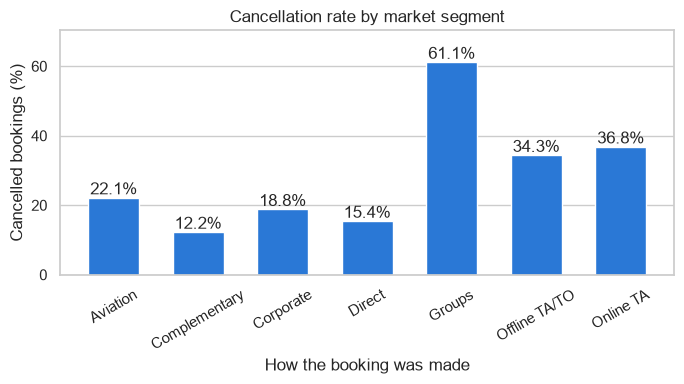

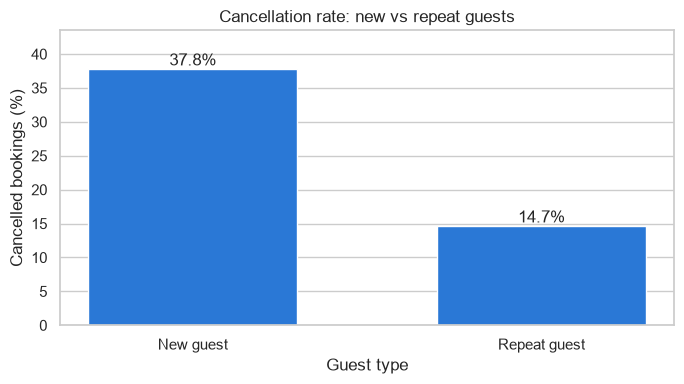

guest_type
New guest       37.805533
Repeat guest    14.651039
Name: mean, dtype: float64

In [8]:
df["guest_type"] = df["is_repeated_guest"].map({0: "New guest", 1: "Repeat guest"})

plot_cancel_rate("deposit_type", "Cancellation rate by deposit type",
                 "Deposit type", "05_cancel_rate_by_deposit_type.png")
plot_cancel_rate("market_segment", "Cancellation rate by market segment",
                 "How the booking was made", "06_cancel_rate_by_market_segment.png", rotate=30)
plot_cancel_rate("guest_type", "Cancellation rate: new vs repeat guests",
                 "Guest type", "07_cancel_rate_by_guest_type.png")

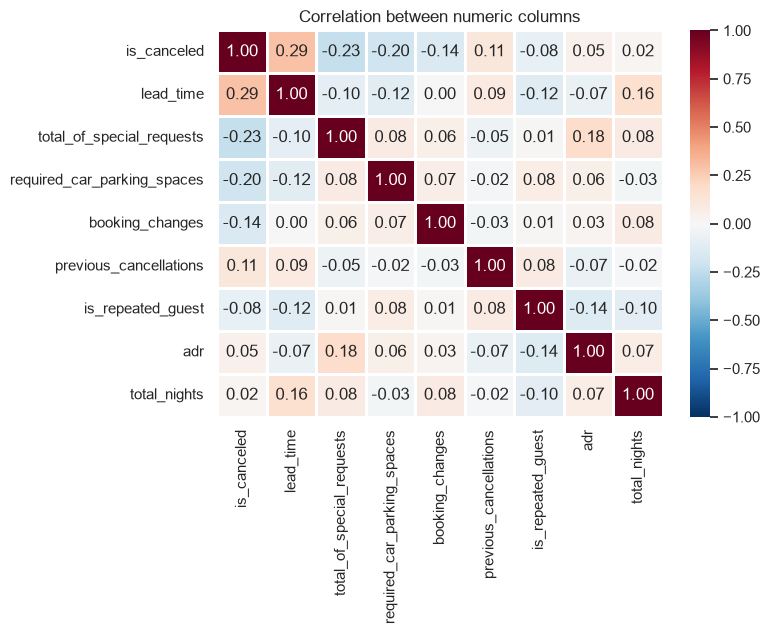

In [9]:
cols = ["is_canceled", "lead_time", "total_of_special_requests", "required_car_parking_spaces",
        "booking_changes", "previous_cancellations", "is_repeated_guest", "adr", "total_nights"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=1, linecolor="white", ax=ax)
ax.set_title("Correlation between numeric columns")
plt.tight_layout()
plt.savefig("../images/08_correlation_heatmap.png", dpi=150)
plt.show()

## Key findings from EDA
1. **Hotel:** City Hotel cancels far more often (41.8%) than Resort Hotel (27.8%).
2. **Lead time:** the strongest pattern. 9.6% of last-minute bookings (0–7 days) cancel vs 57% of bookings made 6+ months ahead.
3. **Season:** cancellations peak April–October (~38–42%) and are lowest in winter (~30–33%).
4. **Special requests:** guests with 0 requests cancel 47.8% of the time; with 1+ requests, 22% or less.
5. **Deposit:** non-refundable bookings cancel 99.4%, mostly group / travel-agent room blocks.
6. **Segment:** Groups cancel most (61.1%); Direct (15.4%) and Corporate (18.8%) least.
7. **Loyalty:** repeat guests cancel 14.7% vs 37.8% for new guests.
8. **Warning:** guests needing parking *never* cancel (0 of 7,409), which is suspicious. Possibly recorded at arrival (leakage risk).

*Correlation is not causation: these are patterns, not proof of cause.*